# TMDB Movie Data Analysis
Pipeline: fetch → clean → analyze → visualize. All the code lives in the `src/` folder.

In [1]:
import sys
import os
import pandas as pd
from dotenv import load_dotenv

# Make sure the notebook runs from the project folder
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.path.abspath("."))

# Import functions to collect, clean, and save movie data
from src.fetch_movies import fetch_movies
from src.clean_movies import clean_dataframe, inspect_columns, add_metrics
from src.validate_clean_data import save_clean_data

# Import functions to explore and analyze the movies
from src.explore_movies import print_basic_info
from src.analyze_kpis import show_all_kpis
from src.compare_franchises import compare_franchise_vs_standalone
from src.analyze_franchises import analyze_franchise_performance
from src.analyze_directors import analyze_director_performance

# Import the two required searches
from src.search_bruce_willis import find_bruce_willis
from src.search_uma_thurman import find_uma_thurman

# Import the chart functions
from src.visualize import (
    plot_revenue_vs_budget,
    plot_roi_by_genre,
    plot_popularity_vs_rating,
    plot_yearly_box_office,
    plot_franchise_vs_standalone,
    plot_top_10_revenue,
)

# Load the API key from the .env file
load_dotenv()
API_KEY = os.getenv("TMDB_API_KEY")

## 1. Fetch
We ask the API for all 19 IDs. ID `0` is not a real movie, so the API answers 404: it is logged and skipped.
Each request waits at most 10 seconds and is tried up to 3 times if it fails.

In [2]:
movie_id = [
    0, 299534, 19995, 140607, 299536, 597, 135397,
    420818, 24428, 168259, 99861, 284054, 12445,
    181808, 330457, 351286, 109445, 321612, 260513
]

movies = fetch_movies(movie_id, API_KEY)
print(f"Loaded {len(movies)} of {len(movie_id)} movies.")

2026-10-25 21:32:11,844 | INFO | Loading movies from the saved file data/raw/tmdb_movies_raw.json


Loaded 18 of 19 movies.


In [3]:
# The ID that failed (saved during the fetch)
print(open("data/raw/fetch_failures.json").read())

[0]


## 2. Clean & Save

In [4]:
clean_df = clean_dataframe(movies)
clean_df.head()

Shape before cleaning: (18, 28)
Shape after cleaning: (18, 22)


,id,title,tagline,release_date,genres,belongs_to_collection,original_language,budget_musd,revenue_musd,production_companies,...,vote_average,popularity,runtime,overview,spoken_languages,poster_path,cast,cast_size,director,crew_size
0,299534,Avengers: Endgame,Avenge the fallen.,2019-04-24,Adventure|Science Fiction|Action,The Avengers Collection,en,356.0,2938.567784,Marvel Studios,...,8.247,88.1465,181,After the devastating events of Avengers: Infi...,English|Japanese|Xhosa,/bR8ISy1O9XQxqiy0fQFw2BX72RQ.jpg,Robert Downey Jr.|Chris Evans|Mark Ruffalo|Chr...,103,Anthony Russo|Joe Russo,614
1,19995,Avatar,Enter the world of Pandora.,2009-12-16,Science Fiction|Action|Adventure,Avatar Collection,en,237.0,2923.706026,Dune Entertainment|Lightstorm Entertainment|20...,...,7.611,46.3413,162,"In the 22nd century, a paraplegic Marine is di...",English|Spanish,/gKY6q7SjCkAU6FqvqWybDYgUKIF.jpg,Sam Worthington|Zoe Saldaña|Sigourney Weaver|S...,68,James Cameron,999
2,140607,Star Wars: The Force Awakens,Every generation has a story.,2015-12-15,Adventure|Action|Science Fiction,Star Wars Collection,en,245.0,2068.223624,Lucasfilm Ltd.|Bad Robot,...,7.239,24.6035,136,Thirty years after defeating the Galactic Empi...,English,/wqnLdwVXoBjKibFRR5U3y0aDUhs.jpg,Daisy Ridley|John Boyega|Oscar Isaac|Adam Driv...,99,J.J. Abrams,270
3,299536,Avengers: Infinity War,An entire universe. Once and for all.,2018-04-25,Adventure|Action|Science Fiction,The Avengers Collection,en,300.0,2052.415039,Marvel Studios,...,8.246,80.2100,149,As the Avengers and their allies have continue...,English|Xhosa,/7WsyChQLEftFiDOVTGkv3hFpyyt.jpg,Robert Downey Jr.|Chris Evans|Chris Hemsworth|...,69,Anthony Russo|Joe Russo,738
4,597,Titanic,Nothing on earth could come between them.,1997-12-18,Drama|Romance,NaN,en,200.0,2264.162353,Paramount Pictures|20th Century Fox|Lightstorm...,...,7.901,60.2206,194,101-year-old Rose DeWitt Bukater tells the sto...,English|French|German|Swedish|Italian|Russian,/9xjZS2rlVxm8SFx8kPC3aIGCOYQ.jpg,Leonardo DiCaprio|Kate Winslet|Billy Zane|Kath...,116,James Cameron,271


In [5]:
# Check the extracted columns with value_counts()
inspect_columns(clean_df)


--- belongs_to_collection ---
belongs_to_collection
The Avengers Collection     4
Star Wars Collection        2
Jurassic Park Collection    2
Frozen Collection           2
Avatar Collection           1
Name: count, dtype: int64

--- genres ---
genres
Adventure          15
Science Fiction    10
Action             10
Family              5
Animation           4
Name: count, dtype: int64

--- production_countries ---
production_countries
United States of America    18
United Kingdom               2
Name: count, dtype: int64

--- production_companies ---
production_companies
Marvel Studios              5
Universal Pictures          3
Lightstorm Entertainment    2
20th Century Fox            2
Lucasfilm Ltd.              2
Name: count, dtype: int64

--- spoken_languages ---
spoken_languages
English    18
Xhosa       3
Russian     3
Spanish     2
French      2
Name: count, dtype: int64


In [6]:
# Save the cleaned data and check the saved file
save_clean_data(clean_df)

Saved cleaned data to: data/processed/tmdb_movies_clean.csv
Rows and columns: (18, 22)
Columns in the right order: True
Duplicate ids: 0


### Explore the data

In [7]:
# Add profit, ROI, franchise and year columns
df = add_metrics(clean_df)
print_basic_info(df)

--- First 5 Movies ---
                          title  release_year  budget_musd  revenue_musd  \
0             Avengers: Endgame          2019        356.0   2938.567784   
1                        Avatar          2009        237.0   2923.706026   
2  Star Wars: The Force Awakens          2015        245.0   2068.223624   
3        Avengers: Infinity War          2018        300.0   2052.415039   
4                       Titanic          1997        200.0   2264.162353   

   vote_average  
0         8.247  
1         7.611  
2         7.239  
3         8.246  
4         7.901  

--- Numeric Summary ---
       budget_musd  revenue_musd  runtime  vote_average  popularity
count        18.00         18.00    18.00         18.00       18.00
mean        213.78       1699.66   138.00          7.40       38.06
std          61.96        539.11    23.85          0.53       21.21
min         125.00       1243.23   102.00          6.52       19.32
25%         162.50       1336.18   125.25      

All 18 movies are big hits (each earned more than $1.2B). Only 2 movies are standalone
(*Titanic* and *Beauty and the Beast*) and most movies are from 2015 to 2019.

## 3. Rankings
`rank_movies()` is used for all 10 KPIs. ROI only uses movies with a budget of at least $10M,
and ratings only use movies with at least 10 votes.

In [8]:
show_all_kpis(df)

Highest Revenue:
                           title  revenue_musd
0             Avengers: Endgame   2938.567784
1                        Avatar   2923.706026
4                       Titanic   2264.162353
2  Star Wars: The Force Awakens   2068.223624
3        Avengers: Infinity War   2052.415039 

Highest Budget:
                            title  budget_musd
0              Avengers: Endgame        356.0
3         Avengers: Infinity War        300.0
12      Star Wars: The Last Jedi        300.0
6                  The Lion King        260.0
2   Star Wars: The Force Awakens        245.0 

Highest Profit:
                           title  profit_musd
1                        Avatar  2686.706026
0             Avengers: Endgame  2582.567784
4                       Titanic  2064.162353
2  Star Wars: The Force Awakens  1823.223624
3        Avengers: Infinity War  1752.415039 

Lowest Profit:
                              title  profit_musd
12        Star Wars: The Last Jedi  1034.407706
17      

## 4. Searches & Comparison

In [9]:
# Search 1: Science Fiction Action movies starring Bruce Willis (best rated first)
find_bruce_willis(df)

,title,genres,vote_average


In [10]:
# Search 2: Uma Thurman movies directed by Quentin Tarantino (shortest first)
find_uma_thurman(df)

,title,director,runtime


Both searches are empty. None of the 18 movies has Bruce Willis or Uma Thurman in the cast,
and none was directed by Quentin Tarantino, so an empty result is the correct answer:

In [11]:
print("Movies with Bruce Willis:", df["cast"].str.contains("Bruce Willis").sum())
print("Movies with Uma Thurman:", df["cast"].str.contains("Uma Thurman").sum())
print("Movies by Quentin Tarantino:", df["director"].str.contains("Quentin Tarantino").sum())

Movies with Bruce Willis: 0
Movies with Uma Thurman: 0
Movies by Quentin Tarantino: 0


In [12]:
# Franchise vs standalone
compare_franchise_vs_standalone(df)

,Movies,Mean_Revenue,Median_ROI,Mean_Budget,Mean_Popularity,Mean_Rating
is_franchise,,,,,,
Standalone,2,1765.14,9.62,180.0,40.67,7.44
Franchise,16,1691.47,7.84,218.0,37.73,7.39


Franchises spend more on average, but the 2 standalone movies have a higher median ROI and are slightly more popular.

## 5. Deep Dives

In [13]:
# Most successful franchises
analyze_franchise_performance(df)

,Movies,Total_Budget,Mean_Budget,Total_Revenue,Mean_Revenue,Mean_Rating
belongs_to_collection,,,,,,
The Avengers Collection,4,1111.0,277.75,7915.20,1978.80,7.96
Star Wars Collection,2,545.0,272.50,3402.63,1701.32,6.98
Jurassic Park Collection,2,320.0,160.00,2982.01,1491.00,6.61
Avatar Collection,1,237.0,237.00,2923.71,2923.71,7.61
Frozen Collection,2,300.0,150.00,2727.90,1363.95,7.23
The Lion King (Reboot) Collection,1,260.0,260.00,1662.02,1662.02,7.09
The Fast and the Furious Collection,1,190.0,190.00,1515.40,1515.40,7.21
Black Panther Collection,1,200.0,200.00,1349.93,1349.93,7.36
Harry Potter Collection,1,125.0,125.00,1341.51,1341.51,8.08


In [14]:
# Most successful directors
analyze_director_performance(df)

,Total_Movies,Total_Revenue,Mean_Rating
director,,,
James Cameron,2,5187.87,7.76
Anthony Russo|Joe Russo,2,4990.98,8.25
Joss Whedon,2,2924.22,7.68
Chris Buck|Jennifer Lee,2,2727.90,7.23
J.J. Abrams,1,2068.22,7.24
Colin Trevorrow,1,1671.54,6.70
Jon Favreau,1,1662.02,7.09
James Wan,1,1515.40,7.21
Ryan Coogler,1,1349.93,7.36


## 6. Visualizations

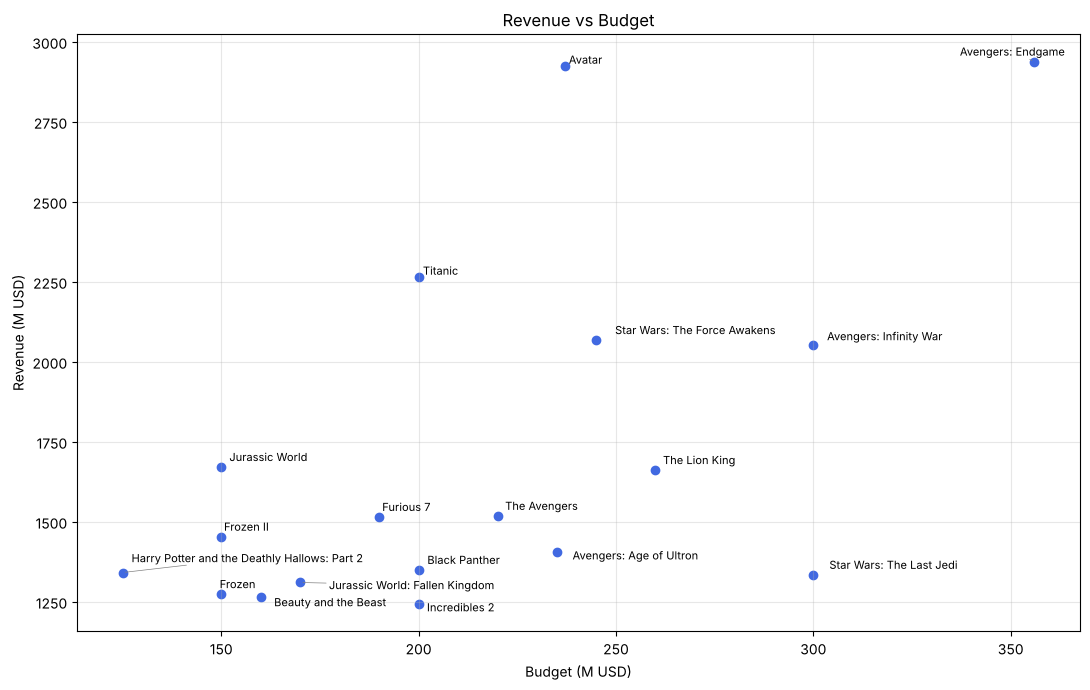

In [15]:
plot_revenue_vs_budget(df)

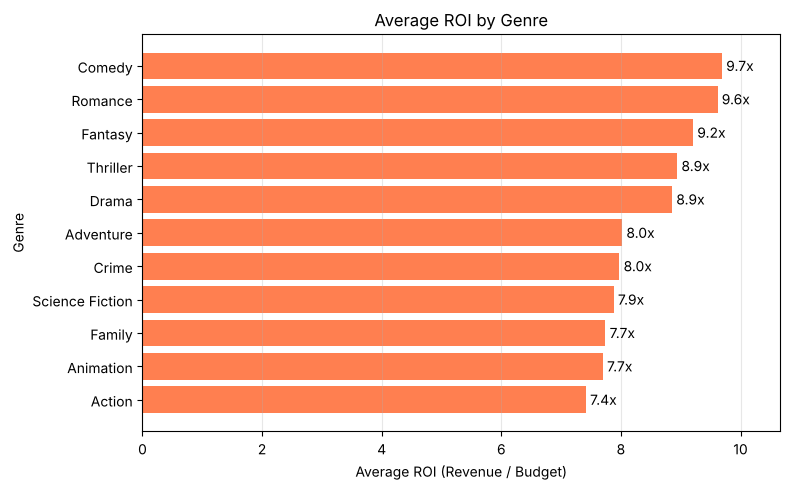

In [16]:
plot_roi_by_genre(df)

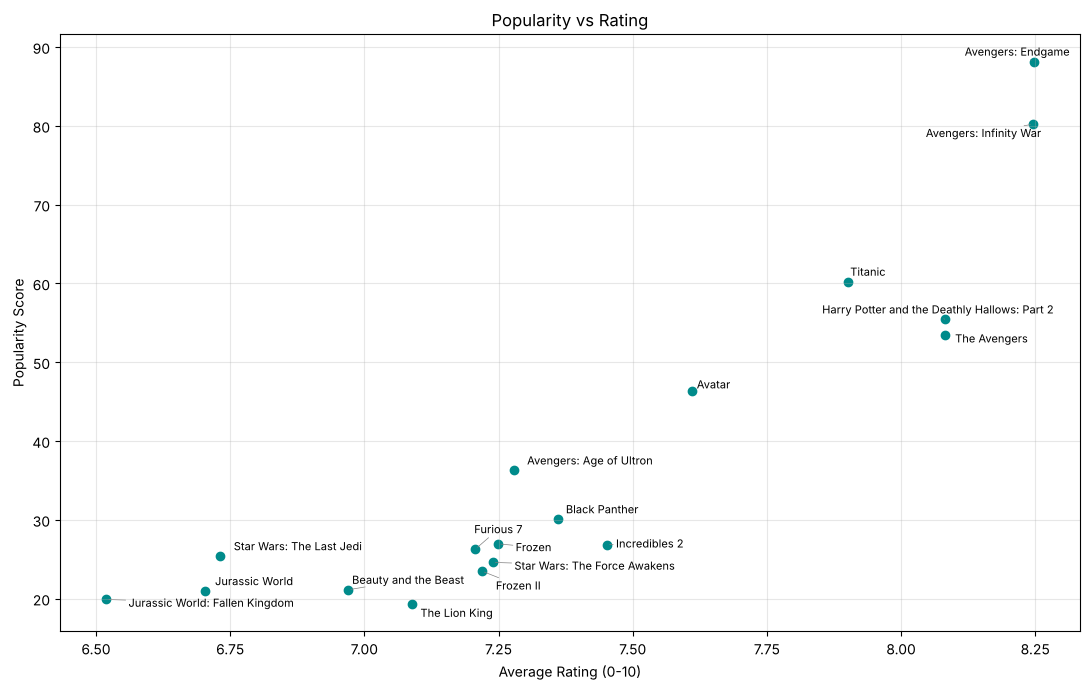

In [17]:
plot_popularity_vs_rating(df)

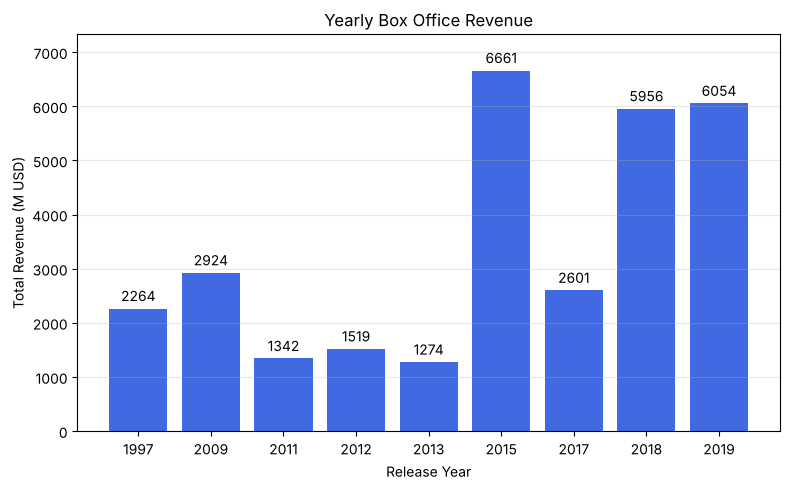

In [18]:
plot_yearly_box_office(df)

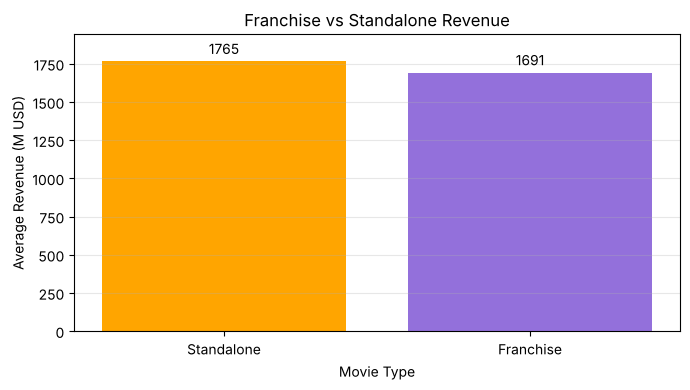

In [19]:
plot_franchise_vs_standalone(df)

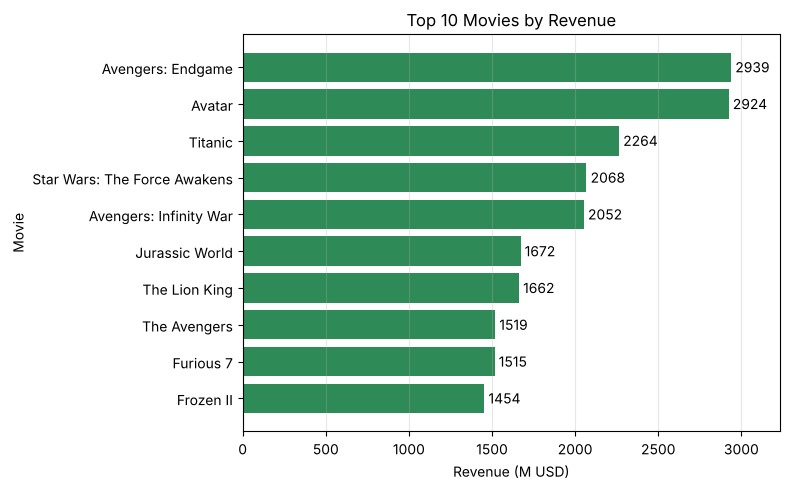

In [20]:
plot_top_10_revenue(df)

## Conclusions
- **Avengers: Endgame** earned the most ($2,939M). **Avatar** had the highest profit ($2,687M) and ROI (12.3x).
- **The Avengers Collection** is the most successful franchise ($7,915M from 4 movies).
- **James Cameron** is the top director by revenue ($5,188M).
- More popular movies also have higher ratings (correlation 0.90).
- This is only 18 blockbusters, so the results describe this list, not all movies.
- Numbers come from the TMDb fetch on 25 October 2026; votes and popularity change daily.